# Implementation and Time Analysis of the Coin Change (Making Change) Problem using Dynamic Programming

The **Coin Change / Making Change** problem has two classic variants, both solved here:

1. **Minimum Coins Problem** — Given a set of coin denominations and a target amount, find the *minimum number of coins* needed to make that amount (unlimited supply of each coin).
2. **Counting Ways Problem** — Given a set of coin denominations and a target amount, find the *number of distinct ways* to make that amount.

For each variant you will find:
- A naive recursive (brute-force) implementation, to show why DP is needed
- A **Dynamic Programming (bottom-up / tabulation)** implementation
- User input (enter your own coin denominations and target amount)
- Runtime measurement (using `time` module)
- Time Complexity and Space Complexity
- A runtime comparison between naive recursion and DP as the amount grows


In [1]:
# Common imports used throughout the notebook
import time
import sys
import matplotlib.pyplot as plt

sys.setrecursionlimit(10000)

def get_user_coins(demo_string=None):
    """Takes a comma-separated list of coin denominations.

    - Interactive use: call get_user_coins() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own coins.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter coin denominations separated by commas (e.g., 1,2,5): "
    )
    try:
        coins = [int(x.strip()) for x in raw.split(',') if x.strip() != '']
        coins = [c for c in coins if c > 0]
        if not coins:
            raise ValueError
    except ValueError:
        print("Invalid input detected, using default coins [1, 2, 5] instead.")
        coins = [1, 2, 5]
    return coins


def get_user_amount(demo_value=None):
    """Takes the target amount to make change for."""
    raw = demo_value if demo_value is not None else input("Enter the target amount: ")
    try:
        amount = int(raw)
        if amount < 0:
            raise ValueError
    except ValueError:
        print("Invalid input detected, defaulting amount to 11.")
        amount = 11
    return amount


## Part A: Minimum Number of Coins

**Problem:** Given coin denominations `coins = [c1, c2, ..., ck]` (unlimited supply
of each) and a target `amount`, find the minimum number of coins needed to make
exactly `amount`. If it's not possible, return -1.


### A.1 Naive Recursive Solution

Tries every coin at every step and recurses on the remaining amount, taking the
minimum over all choices. This re-solves the same sub-amounts many times —
hence the exponential blow-up.


In [2]:
def min_coins_recursive(coins, amount):
    if amount == 0:
        return 0
    if amount < 0:
        return float('inf')

    best = float('inf')
    for coin in coins:
        result = min_coins_recursive(coins, amount - coin)
        if result != float('inf'):
            best = min(best, result + 1)
    return best


### A.2 Dynamic Programming (Bottom-Up Tabulation)

Build a table `dp[a]` = minimum coins needed to make amount `a`, for every `a`
from `0` up to the target `amount`. `dp[0] = 0` (base case: zero coins needed
for amount 0). For each amount `a`, try every coin `c <= a` and take the best:
`dp[a] = min(dp[a], dp[a - c] + 1)`.

Each sub-amount is computed **once** and reused — this is what eliminates the
repeated work of the naive recursion.


In [3]:
def min_coins_dp(coins, amount):
    INF = float('inf')
    dp = [0] + [INF] * amount   # dp[0..amount]

    for a in range(1, amount + 1):
        for coin in coins:
            if coin <= a and dp[a - coin] + 1 < dp[a]:
                dp[a] = dp[a - coin] + 1

    return dp[amount] if dp[amount] != INF else -1


In [4]:
# --- Minimum Coins: User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_coins() / get_user_amount(),
# to type your own coins and amount interactively.
coins = get_user_coins("1,2,5")
amount = get_user_amount("11")

print("Coins  :", coins)
print("Amount :", amount)

start = time.time()
result_recursive = min_coins_recursive(coins, amount)
end = time.time()
print(f"\nNaive Recursive -> Min coins: {result_recursive}  |  Runtime: {(end - start) * 1000:.4f} ms")

start = time.time()
result_dp = min_coins_dp(coins, amount)
end = time.time()
print(f"Dynamic Programming -> Min coins: {result_dp}  |  Runtime: {(end - start) * 1000:.4f} ms")


Coins  : [1, 2, 5]
Amount : 11

Naive Recursive -> Min coins: 3  |  Runtime: 0.3042 ms
Dynamic Programming -> Min coins: 3  |  Runtime: 0.0372 ms


**Naive Recursive**
- Time Complexity: `O(k^amount)` where `k` is the number of coin denominations — exponential, since each of the `amount` levels branches into `k` recursive calls.
- Space Complexity: `O(amount)` for the recursion call stack depth.

**Dynamic Programming (Tabulation)**
- Time Complexity: `O(amount * k)` — the outer loop runs `amount` times, and for each amount we try all `k` coins.
- Space Complexity: `O(amount)` — for the `dp` array of size `amount + 1`.

DP turns an exponential problem into a polynomial one by storing and reusing the answer to each sub-amount exactly once (this is the core idea of dynamic programming: **overlapping subproblems** + **optimal substructure**).


## Part B: Counting the Number of Ways to Make Change

**Problem:** Given coin denominations (unlimited supply of each) and a target
`amount`, count the number of *distinct combinations* of coins that add up to
`amount`. (Order doesn't matter — `{1,2,2}` and `{2,1,2}` count as the same combination.)


### B.1 Naive Recursive Solution

Recurses by deciding, for each coin (processed in a fixed order), how many times
to use it before moving to the next coin — this avoids counting the same
combination in a different order more than once.


In [5]:
def count_ways_recursive(coins, amount, index=0):
    if amount == 0:
        return 1
    if amount < 0 or index >= len(coins):
        return 0

    # Either use one instance of coins[index] and stay on the same coin,
    # or skip to the next coin denomination entirely.
    include = count_ways_recursive(coins, amount - coins[index], index)
    exclude = count_ways_recursive(coins, amount, index + 1)
    return include + exclude


### B.2 Dynamic Programming (Bottom-Up Tabulation)

Build `dp[a]` = number of ways to make amount `a`. Start with `dp[0] = 1` (one
way to make amount 0: use no coins). Process coins **one at a time**, and for
each coin, update all amounts from `coin` up to `amount` in increasing order —
this ensures each combination is only counted once (not as different
permutations of the same coins).


In [6]:
def count_ways_dp(coins, amount):
    dp = [0] * (amount + 1)
    dp[0] = 1

    for coin in coins:
        for a in range(coin, amount + 1):
            dp[a] += dp[a - coin]

    return dp[amount]


In [7]:
# --- Counting Ways: User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_coins() / get_user_amount(),
# to type your own coins and amount interactively.
coins = get_user_coins("1,2,5")
amount = get_user_amount("11")

print("Coins  :", coins)
print("Amount :", amount)

start = time.time()
ways_recursive = count_ways_recursive(coins, amount)
end = time.time()
print(f"\nNaive Recursive -> Ways: {ways_recursive}  |  Runtime: {(end - start) * 1000:.4f} ms")

start = time.time()
ways_dp = count_ways_dp(coins, amount)
end = time.time()
print(f"Dynamic Programming -> Ways: {ways_dp}  |  Runtime: {(end - start) * 1000:.4f} ms")


Coins  : [1, 2, 5]
Amount : 11

Naive Recursive -> Ways: 11  |  Runtime: 0.0513 ms
Dynamic Programming -> Ways: 11  |  Runtime: 0.0350 ms


**Naive Recursive**
- Time Complexity: `O(2^amount)` in the worst case (each amount either includes or excludes a coin, branching).
- Space Complexity: `O(amount)` recursion stack depth.

**Dynamic Programming (Tabulation)**
- Time Complexity: `O(amount * k)` — for each of the `k` coins, we scan up to `amount` positions.
- Space Complexity: `O(amount)` — for the `dp` array.


## Runtime Comparison: Naive Recursion vs Dynamic Programming

Using the Minimum Coins problem, the cell below times the naive recursive
solution against the DP solution for increasing target amounts. The naive
version grows so slowly-scaling amounts are used deliberately, since its
exponential blow-up would take far too long at larger amounts.


In [8]:
# --- Compare naive recursion vs DP as amount grows ---
coins_for_comparison = [1, 2, 5]
amounts = [5, 10, 15, 20, 22]   # kept small - naive recursion is exponential!

recursive_times = []
dp_times = []

for amt in amounts:
    start = time.time()
    min_coins_recursive(coins_for_comparison, amt)
    recursive_times.append((time.time() - start) * 1000)

    start = time.time()
    min_coins_dp(coins_for_comparison, amt)
    dp_times.append((time.time() - start) * 1000)

print(f"{'Amount':<10}{'Recursive (ms)':<18}{'DP (ms)':<12}")
for amt, rt, dt in zip(amounts, recursive_times, dp_times):
    print(f"{amt:<10}{rt:<18.4f}{dt:<12.4f}")


Amount    Recursive (ms)    DP (ms)     
5         0.0176            0.0052      
10        0.1309            0.0038      
15        1.8158            0.0052      
20        26.3610           0.0103      
22        76.4771           0.0148      


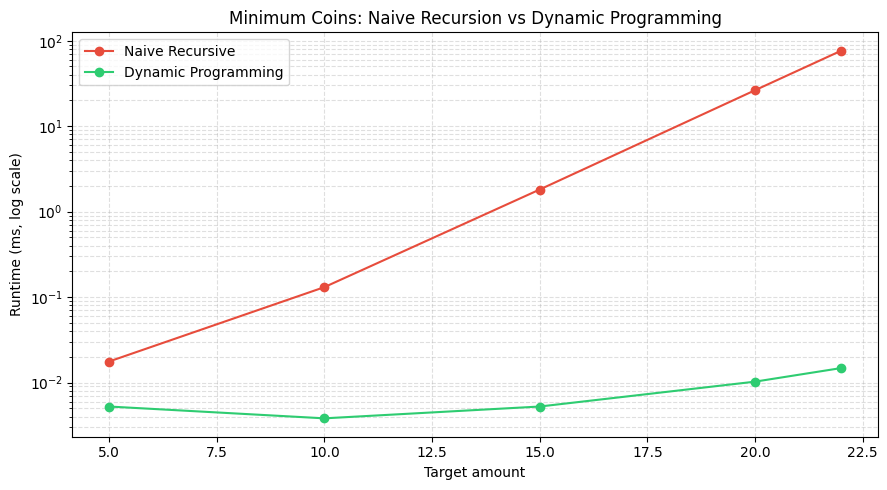

In [9]:
# --- Line chart (log scale on y-axis to show the exponential vs polynomial gap) ---
plt.figure(figsize=(9, 5))
plt.plot(amounts, recursive_times, marker='o', label='Naive Recursive', color='#e74c3c')
plt.plot(amounts, dp_times, marker='o', label='Dynamic Programming', color='#2ecc71')
plt.yscale('log')
plt.xlabel("Target amount")
plt.ylabel("Runtime (ms, log scale)")
plt.title("Minimum Coins: Naive Recursion vs Dynamic Programming")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Approach                  | Min Coins Time | Counting Ways Time | Space   |
|----------------------------|----------------|----------------------|---------|
| Naive Recursive            | O(k^amount)    | O(2^amount)          | O(amount) (stack) |
| Dynamic Programming (DP)   | O(amount × k)  | O(amount × k)        | O(amount) |

Where `k` = number of coin denominations, `amount` = target value.

**Notes:**
- Both problems have **optimal substructure** (the best/total answer for `amount` is built from answers to smaller amounts) and **overlapping subproblems** (the same smaller amounts get asked about repeatedly) — the two properties that make dynamic programming applicable.
- The naive recursive solutions recompute the same sub-amounts over and over; DP computes each sub-amount exactly once and reuses it, turning exponential time into polynomial time.
- Both DP solutions here use `O(amount)` space for a 1D table — this is a common and memory-efficient pattern (no need for a full 2D `coins × amount` table since we only ever need the previous row/values).
- A memoized (top-down) recursive version would also achieve `O(amount × k)` time — the DP tabulation shown here is the equivalent bottom-up form.
